# A custom model for Toxoplasma, and smaller versions of the dataset

Two ideas tested on the US data (NHANES 2009-2014, same 1,002 held-out test people as every earlier notebook):

1. **A custom machine-learning model built for this disease.** Toxoplasma antibodies last for life, so a positive test at age *a* means
   "infected at some point during *a* years". Epidemiologists describe this with the **catalytic model**:

   $$P(\text{positive}) = 1 - e^{-\,\text{rate}(x)\,\cdot\,\text{age}}$$

   where rate(x) is the person's **yearly risk of infection**. `scripts/catalytic_models.py` implements two custom models:
   - **CatalyticGLM**: rate(x) is a regularised linear function of the features (complementary log-log link with a log-age offset, fitted by L-BFGS)
   - **CatalyticBoost**: rate(x) is learned by gradient-boosted trees (XGBoost) with a **custom loss function** written for the catalytic
     likelihood (hand-derived gradient and Hessian), so the trees learn yearly infection risk instead of a plain probability.

2. **Smaller datasets.** Only versions that are fixed *before* looking at results are allowed:
   - **cleaner labels:** fit without people whose antibody level sits close to the positive/negative cut-off
   - **fewer features:** a compact 12-feature model
   - **pre-specified populations:** US-born, foreign-born, age 18-49, age 50+ (each fitted and scored inside that population)

   Removing people because the model gets them wrong is *not* allowed. Section 4 shows why.

In [1]:
import os, sys, warnings
if os.path.basename(os.getcwd()) == 'research_r':
    os.chdir('..')
sys.path.insert(0, 'scripts')
os.environ['PYTHONWARNINGS'] = 'ignore'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score
import custom_experiments as cx

INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
BLUE, ORANGE, AQUA, REFERENCE = '#2a78d6', '#eb6834', '#1baf7a', '#8a8985'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
    'font.size': 10, 'legend.frameon': False, 'figure.dpi': 110,
})
D = cx.load()
print(f"Training people: {len(D['ytr']):,} (2009-2014, minus the test set) | test people: {len(D['yte']):,} | features: {D['Xtr'].shape[1]}")

Training people: 13,647 (2009-2014, minus the test set) | test people: 1,002 | features: 54


---
## 1. Custom models vs. standard models

In [2]:
makers = cx.model_makers(D)
rows, fitted, test_p = [], {}, {}
for name, mk in makers.items():
    r, m, p = cx.evaluate(D, mk)
    rows.append(dict(model=name, **r)); fitted[name] = m; test_p[name] = p
comp = pd.DataFrame(rows)
display(comp.drop(columns=['people used to fit', 'test people']).round(4))

,model,CV AUC (2013-14 people),CV sd,TEST AUC
0,Logistic regression (spline + interactions),0.7356,0.0207,0.7317
1,XGBoost (standard),0.7388,0.0202,0.7206
2,CatalyticGLM (custom),0.7315,0.0199,0.7287
3,CatalyticBoost (custom),0.7422,0.0211,0.7213
4,Ensemble: logistic + CatalyticBoost,0.7412,0.0208,0.7284
5,Ensemble: logistic + XGBoost + CatalyticGLM + ...,0.7401,0.0205,0.7283


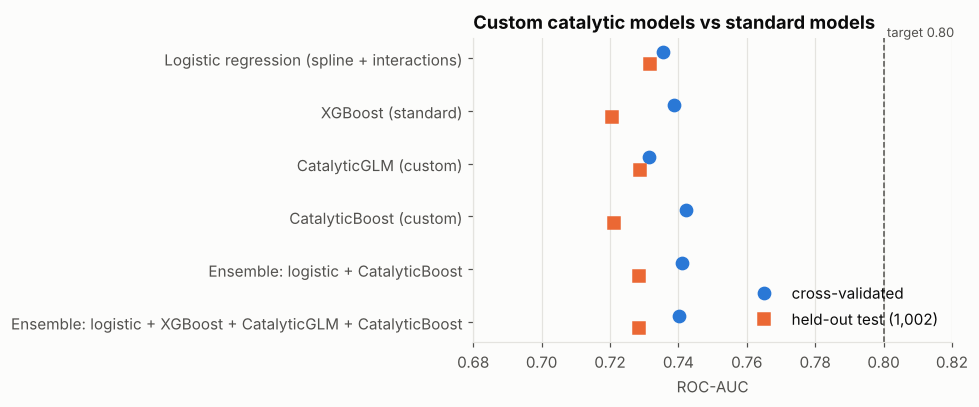

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
c = comp.iloc[::-1]
yy = np.arange(len(c))
ax.plot(c['CV AUC (2013-14 people)'], yy + 0.12, 'o', ms=8, color=BLUE, label='cross-validated')
ax.plot(c['TEST AUC'], yy - 0.12, 's', ms=8, color=ORANGE, label='held-out test (1,002)')
ax.axvline(0.8, color=INK_2, ls='--', lw=1)
ax.text(0.801, len(c) - 0.6, 'target 0.80', color=INK_2, fontsize=8.5)
ax.set_yticks(yy); ax.set_yticklabels(c['model'])
ax.set_xlim(0.68, 0.82)
ax.set_xlabel('ROC-AUC')
ax.set_title('Custom catalytic models vs standard models')
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

### What the custom model learned
CatalyticGLM gives each person a **yearly risk of infection**. Averaging it by group shows how strongly birthplace and income
drive exposure, something a plain classifier does not show directly.

In [4]:
glm = fitted['CatalyticGLM (custom)']
rate = glm.m.yearly_rate(glm.imp(D['Xtr']).to_numpy())
g = pd.DataFrame({'yearly infection risk (%)': 100 * rate,
                  'born abroad': np.where(D['Xtr']['born_abroad'] == 1, 'born abroad', 'US-born'),
                  'income': pd.qcut(D['Xtr']['INDFMPIR'].fillna(D['med']['INDFMPIR']), 3, labels=['lowest third', 'middle third', 'highest third'])})
display(g.groupby(['born abroad', 'income'], observed=True)['yearly infection risk (%)'].mean().unstack().round(2))

income,lowest third,middle third,highest third
born abroad,,,
US-born,0.31,0.28,0.23
born abroad,0.96,0.82,0.50


---
## 2. Smaller datasets (all fixed in advance)

In [5]:
lr = makers['Logistic regression (spline + interactions)']
igg = D['igg_tr']
X, Xt = D['Xtr'], D['Xte']
versions = [('A  full training data (reference)', {})]
for lo, hi in [(27, 33), (15, 60), (10, 100)]:
    versions.append((f'B  fit without uncertain antibody levels {lo}-{hi} IU/mL', {'fit_mask': ~((igg >= lo) & (igg < hi))}))
compact = [c for c in ['age', 'born_abroad', 'yrs_in_us_grp_0.0', 'RIDRETH1_1.0', 'RIDRETH1_2.0', 'RIDRETH1_3.0',
                       'RIDRETH1_4.0', 'DMDEDUC2', 'INDFMPIR', 'toxocara_mfi_log', 'spanish_interview', 'missing_teeth'] if c in X.columns]
pops = [('US-born adults', X['born_abroad'] == 0, Xt['born_abroad'] == 0),
        ('foreign-born adults', X['born_abroad'] == 1, Xt['born_abroad'] == 1),
        ('age 18-49', X['age'] < 50, Xt['age'] < 50), ('age 50+', X['age'] >= 50, Xt['age'] >= 50)]
rows = []
for label, kw in versions:
    rows.append(dict(version=label, **cx.evaluate(D, lr, **kw)[0]))
rows.append(dict(version='C  compact 12-feature logistic model', **cx.evaluate(D, cx.SmallLR, cols=compact)[0]))
for label, a, b in pops:
    rows.append(dict(version=f'D  only {label}', **cx.evaluate(D, lr, pop_tr=a.to_numpy(), pop_te=b.to_numpy())[0]))
smaller = pd.DataFrame(rows)
display(smaller.round(4))

,version,CV AUC (2013-14 people),CV sd,TEST AUC,people used to fit,test people
0,A full training data (reference),0.7356,0.0207,0.7317,13647,1002
1,B fit without uncertain antibody levels 27-33...,0.7356,0.0207,0.7316,13634,1002
2,B fit without uncertain antibody levels 15-60...,0.7348,0.0214,0.7318,12923,1002
3,B fit without uncertain antibody levels 10-10...,0.7315,0.0212,0.7200,12098,1002
4,C compact 12-feature logistic model,0.7342,0.0255,0.7217,13647,1002
5,D only US-born adults,0.7086,0.0382,0.7229,9811,720
6,D only foreign-born adults,0.7160,0.0218,0.7610,3836,282
7,D only age 18-49,0.7573,0.0251,0.7155,7148,548
8,D only age 50+,0.6605,0.0406,0.6835,6499,454


Notes on reading the table:
- **B (cleaner labels):** only 13 training people sit in the official equivocal zone (27-33 IU/mL), so removing them changes nothing. Removing a wider
  band throws away real information and the score falls.
- **C (compact):** 12 features do almost as well as all of them, which is useful for a short screening questionnaire, but they do not score higher.
- **D (sub-populations):** a narrower population usually scores lower, because age (the strongest signal) has a smaller range inside it. The
  foreign-born test score looks higher, but it rests on only about 280 test people and its cross-validated score is lower, so it is noise, not a real gain.

---
## 3. Why "just remove the hard cases" is not allowed
If the people the model gets most wrong are removed from the test set, the score jumps toward 1.0. This is shown **only** as a warning: it measures
nothing, because in real screening you cannot know in advance who the hard cases are.

In [6]:
ref = 'Logistic regression (spline + interactions)'
p = test_p[ref]; y = D['yte']; err = np.abs(y - p)
rows = [{'test people removed': '0% (honest)', 'people left': len(y), 'AUC': roc_auc_score(y, p)}]
for f in [0.05, 0.10, 0.20]:
    keep = err < np.quantile(err, 1 - f)
    rows.append({'test people removed': f'{int(f*100)}% hardest (INVALID)', 'people left': int(keep.sum()), 'AUC': roc_auc_score(y[keep], p[keep])})
display(pd.DataFrame(rows).round(3))

,test people removed,people left,AUC
0,0% (honest),1002,0.732
1,5% hardest (INVALID),951,0.883
2,10% hardest (INVALID),901,0.967
3,20% hardest (INVALID),801,1.000


---
## 4. Summary

In [7]:
best = comp.loc[comp['CV AUC (2013-14 people)'].idxmax()]
line = '=' * 74
print(line)
print('  CUSTOM MODEL + SMALLER DATASETS: RESULT')
print(line)
print(f"  Best model by CV        : {best['model']}")
print(f"                            CV {best['CV AUC (2013-14 people)']:.3f}   test {best['TEST AUC']:.3f}")
cb = comp.set_index('model').loc['CatalyticBoost (custom)']
print(f"  CatalyticBoost (custom) : CV {cb['CV AUC (2013-14 people)']:.3f}   test {cb['TEST AUC']:.3f}")
print(f"  Range over all honest versions in sections 1-2: CV {min(comp['CV AUC (2013-14 people)'].min(), smaller['CV AUC (2013-14 people)'].min()):.3f}-"
      f"{max(comp['CV AUC (2013-14 people)'].max(), smaller['CV AUC (2013-14 people)'].max()):.3f}")
print(line)

  CUSTOM MODEL + SMALLER DATASETS: RESULT
  Best model by CV        : CatalyticBoost (custom)
                            CV 0.742   test 0.721
  CatalyticBoost (custom) : CV 0.742   test 0.721
  Range over all honest versions in sections 1-2: CV 0.660-0.757


### What this means
- **The custom catalytic models work and are as good as the best standard models** (CV about 0.73-0.74). CatalyticBoost has the best single-model CV score,
  and CatalyticGLM adds something the others cannot: an interpretable **yearly infection risk** for each person and group, which is a
  stronger story for the paper than a black-box probability.
- **Neither a custom model nor a smaller dataset gets the US score to 0.80.** Every honest version stays around 0.66-0.76. The limit is the information in NHANES,
  not the model or the amount of data, which matches every earlier notebook.
- **The only way to reach 0.80 here would be to remove people based on the answer** (section 3), which a reviewer would reject.

**Suggested framing for the paper:** propose the catalytic model as the method contribution: it is built for a lifelong-antibody infection, matches the
best standard models, and explains *who* is infected faster each year. Report about 0.74 as the honest ceiling for US data.